# Experiment 4: Hill Climbing
**CSAI4014 AISR Laboratory** | Name: `<Suhani Baderia>` | SAP ID: `<500119327>` | Batch: `<4>`

1. Hill climbing on a 1-D objective with several local maxima – why a greedy climber gets stuck.
2. Plain **steepest-ascent hill climbing on eight queens** (complete-state formulation:
   one queen per column, objective h = number of attacking pairs, goal h = 0).
3. **Random-restart hill climbing**: success rate against the number of restarts k, measured and
   predicted by $P(k) = 1 - (1 - p)^k$ where p is the single-climb success rate.

In [ ]:
import os
import platform
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema

os.makedirs("figs", exist_ok=True)
os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3})
print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| Matplotlib:", matplotlib.__version__)
print("OS    :", platform.platform())
SEED =  9327
rng = np.random.default_rng(SEED)

Python: 3.10.0 | NumPy: 2.2.6 | Matplotlib: 3.10.9
OS    : Windows-10-10.0.26300-SP0


## Part 1 – a 1-D landscape with local maxima
$f(x) = \sin(x) + 0.6\sin(2.7x) + 0.05x$ on $0 \le x \le 12$. A climber takes steps of size
`STEP` towards the better neighbour and stops when neither neighbour is better.

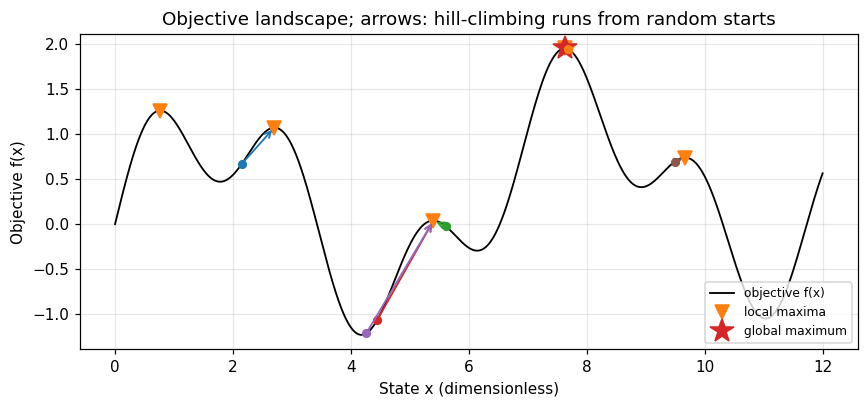

Local maxima (x, f): [(0.77, 1.259), (2.7, 1.069), (5.4, 0.039), (7.63, 1.947), (9.67, 0.738)]
start  2.15 -> stops at x =  2.70, f = 1.069, steps =   55  [local]
start  7.68 -> stops at x =  7.63, f = 1.947, steps =    5  [GLOBAL]
start  5.61 -> stops at x =  5.40, f = 0.039, steps =   21  [local]
start  4.45 -> stops at x =  5.40, f = 0.039, steps =   95  [local]
start  4.26 -> stops at x =  5.40, f = 0.039, steps =  114  [local]
start  9.49 -> stops at x =  9.67, f = 0.738, steps =   18  [local]


In [ ]:
def f(x):
    return np.sin(x) + 0.6 * np.sin(2.7 * x) + 0.05 * x

X_LO, X_HI, STEP = 0.0, 12.0, 0.01
xs = np.arange(X_LO, X_HI + STEP / 2, STEP)
ys = f(xs)
loc_max = argrelextrema(ys, np.greater)[0]
g_idx = loc_max[np.argmax(ys[loc_max])]

def climb_1d(x0):
    x, path = x0, [x0]
    while True:
        cand = [c for c in (x - STEP, x + STEP) if X_LO <= c <= X_HI]
        best = max(cand, key=f)
        if f(best) <= f(x):
            return x, path
        x = best
        path.append(x)

starts = rng.uniform(X_LO, X_HI, 6)
runs_1d = [climb_1d(round(s, 2)) for s in starts]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(xs, ys, color="k", lw=1.2, label="objective f(x)")
ax.plot(xs[loc_max], ys[loc_max], "v", color="tab:orange", ms=9, label="local maxima")
ax.plot(xs[g_idx], ys[g_idx], "*", color="tab:red", ms=16, label="global maximum")
for i, (xe, path) in enumerate(runs_1d):
    ax.plot(path[0], f(path[0]), "o", color=f"C{i}", ms=5)
    ax.annotate("", xy=(xe, f(xe)), xytext=(path[0], f(path[0])),
                arrowprops=dict(arrowstyle="->", color=f"C{i}", lw=1.2))
ax.set_xlabel("State x (dimensionless)")
ax.set_ylabel("Objective f(x)")
ax.set_title("Objective landscape; arrows: hill-climbing runs from random starts")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("figs/fig4_1_objective_landscape.png")
plt.show()

print("Local maxima (x, f):", [(round(float(xs[i]), 2), round(float(ys[i]), 3)) for i in loc_max])
for s, (xe, path) in zip(starts, runs_1d):
    tag = "GLOBAL" if abs(xe - xs[g_idx]) < 2 * STEP else "local"
    print(f"start {s:5.2f} -> stops at x = {xe:5.2f}, f = {f(xe):.3f}, steps = {len(path)-1:4d}  [{tag}]")

## Part 2 – plain steepest-ascent hill climbing on eight queens
State: `board[c]` = row of the queen in column c. Neighbours: move one queen within its column
(8 × 7 = 56 neighbours). We minimise h (= maximise −h). The climber stops when no neighbour has
a strictly lower h (local minimum or plateau), i.e. **no sideways moves** in plain hill climbing.

In [ ]:
N = 8

def attacks(board):
    n, h = len(board), 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == j - i:
                h += 1
    return h

def best_neighbour(board):
    """Return (h_best, col, row) of the best single-queen move; ties broken at random."""
    n = len(board)
    best_h, moves = None, []
    for c in range(n):
        orig = board[c]
        for r in range(n):
            if r == orig:
                continue
            board[c] = r
            h = attacks(board)
            if best_h is None or h < best_h:
                best_h, moves = h, [(c, r)]
            elif h == best_h:
                moves.append((c, r))
        board[c] = orig
    c, r = moves[int(rng.integers(len(moves)))]
    return best_h, c, r

def hill_climb(n=N):
    board = [int(v) for v in rng.integers(0, n, n)]
    h, steps = attacks(board), 0
    while h > 0:
        h_new, c, r = best_neighbour(board)
        if h_new >= h:              # no strictly better neighbour: stuck
            break
        board[c] = r
        h, steps = h_new, steps + 1
    return h == 0, steps, h, board

TRIALS = 1000
t0 = time.perf_counter()
plain = [hill_climb() for _ in range(TRIALS)]
elapsed = time.perf_counter() - t0
succ = np.array([p[0] for p in plain])
steps = np.array([p[1] for p in plain])
final_h = np.array([p[2] for p in plain])
p_hat = succ.mean()
se = np.sqrt(p_hat * (1 - p_hat) / TRIALS)

table_plain = [
    ["Trials", TRIALS],
    ["Successes (h = 0)", int(succ.sum())],
    ["Success rate", f"{100*p_hat:.1f} % ({succ.sum()}/{TRIALS}), ±{100*1.96*se:.1f} % (95% CI)"],
    ["Mean steps when successful", f"{steps[succ].mean():.2f}"],
    ["Mean steps when stuck", f"{steps[~succ].mean():.2f}"],
    ["Mean final h when stuck", f"{final_h[~succ].mean():.2f}"],
    ["Total time / time per climb", f"{elapsed:.2f} s / {1e3*elapsed/TRIALS:.2f} ms"],
]
for k, v in table_plain:
    print(f"{k:<30}{v}")
np.savetxt("tables/T4_1_plain_hill_climbing.csv", np.array(table_plain, dtype=object), fmt="%s",
           delimiter=";", header="Quantity;Value", comments="")
sol = next(p[3] for p in plain if p[0])
print("Example solution found:", sol)

Trials                        1000
Successes (h = 0)             142
Success rate                  14.2 % (142/1000), ±2.2 % (95% CI)
Mean steps when successful    4.15
Mean steps when stuck         3.09
Mean final h when stuck       1.46
Total time / time per climb   1.52 s / 1.52 ms
Example solution found: [6, 2, 7, 1, 4, 0, 5, 3]


## Part 3 – random-restart hill climbing
For each trial we run independent climbs until one succeeds (capped at `K_MAX`). A trial with a
budget of k climbs succeeds if the first success came on climb ≤ k. This uses the **same trials**
for every k, and each percentage is reported with its number of trials. Prediction:
$P(k) = 1-(1-p)^k$ with p from Part 2.

In [ ]:
K_MAX, RR_TRIALS = 30, 500
first_success = np.full(RR_TRIALS, np.inf)
for t in range(RR_TRIALS):
    for k in range(1, K_MAX + 1):
        if hill_climb()[0]:
            first_success[t] = k
            break

ks = np.array([1, 2, 3, 5, 8, 10, 15, 20, 30])
measured = np.array([(first_success <= k).mean() for k in ks])
predicted = 1 - (1 - p_hat) ** ks
rows = []
print(f"{'k':>4}{'Trials':>8}{'Successes':>11}{'Measured %':>12}{'Predicted %':>13}")
for k, m, pr in zip(ks, measured, predicted):
    nsucc = int((first_success <= k).sum())
    rows.append([k, RR_TRIALS, nsucc, 100 * m, 100 * pr])
    print(f"{k:4d}{RR_TRIALS:8d}{nsucc:11d}{100*m:12.1f}{100*pr:13.1f}")
np.savetxt("tables/T4_2_success_vs_restarts.csv", np.array(rows), delimiter=",",
           fmt=["%d", "%d", "%d", "%.1f", "%.1f"],
           header="k,Trials,Successes,Measured %,Predicted %", comments="")
print(f"Mean climbs to first success: {first_success[np.isfinite(first_success)].mean():.2f}"
      f" (geometric prediction 1/p = {1/p_hat:.2f})")

   k  Trials  Successes  Measured %  Predicted %
   1     500         71        14.2         14.2
   2     500        131        26.2         26.4
   3     500        188        37.6         36.8
   5     500        258        51.6         53.5
   8     500        338        67.6         70.6
  10     500        370        74.0         78.4
  15     500        447        89.4         89.9
  20     500        482        96.4         95.3
  30     500        497        99.4         99.0
Mean climbs to first success: 6.98 (geometric prediction 1/p = 7.04)


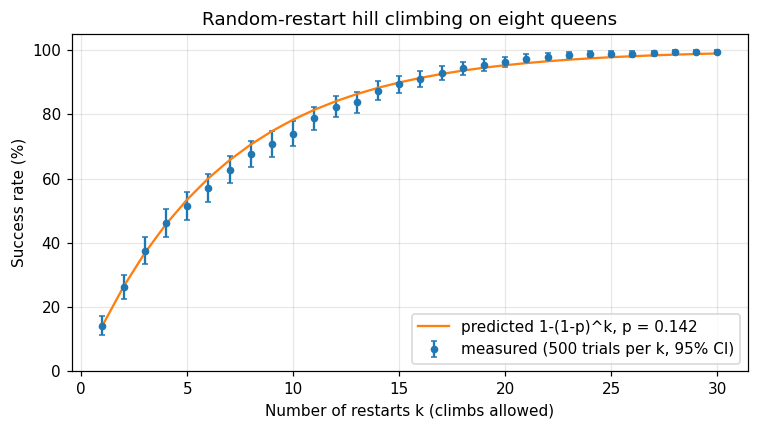

In [ ]:
kk = np.arange(1, K_MAX + 1)
meas_all = np.array([(first_success <= k).mean() for k in kk])
err = 1.96 * np.sqrt(meas_all * (1 - meas_all) / RR_TRIALS)
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(kk, 100 * meas_all, yerr=100 * err, fmt="o", ms=4, capsize=2,
            label=f"measured ({RR_TRIALS} trials per k, 95% CI)")
ax.plot(kk, 100 * (1 - (1 - p_hat) ** kk), "-", lw=1.5,
        label=f"predicted 1-(1-p)^k, p = {p_hat:.3f}")
ax.set_xlabel("Number of restarts k (climbs allowed)")
ax.set_ylabel("Success rate (%)")
ax.set_ylim(0, 105)
ax.set_title("Random-restart hill climbing on eight queens")
ax.legend()
fig.tight_layout()
fig.savefig("figs/fig4_2_success_vs_restarts.png")
plt.show()